In [1]:
from langchain.chat_models import init_chat_model
import langchain_ollama

In [8]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

In [11]:
from pydantic import BaseModel, Field

In [2]:
from langchain.tools import tool

In [3]:
from dataclasses import dataclass
from typing import TypedDict, Optional, Set, List

In [4]:
from rich.console import Console
from rich.panel import Panel
from rich.pretty import Pretty
console = Console()

In [5]:
model = init_chat_model(
    model="qwen3:8b",
    model_provider="ollama",
    temprature = 0
)

In [6]:
def show(stuff : str):
    console.print(Panel(Pretty(stuff)))
    

In [ ]:

class SearchQuery(BaseModel):
    search_query : str = Field(None, description="Query that is optimised web search")
    justification: str = Field(None,justification = "Why tis query is relavent to the user prompt")

structured_llm = model.with_structured_output(SearchQuery)

output = model.invoke("Who is Spiderman")
console.print(Panel(Pretty(output), title="LLM output"))

C:\Users\advai\AppData\Local\Temp\ipykernel_24296\2565705925.py:4: PydanticDeprecatedSince20: Using extra keyword arguments on `Field` is deprecated and will be removed. Use `json_schema_extra` instead. (Extra keys: 'justification'). Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.14/migration/
  justification: str = Field(None,justification = "Why tis query is relavent to the user prompt")


╭────────────────────────────────────────────────── LLM output ───────────────────────────────────────────────────╮
│ AIMessage(                                                                                                      │
│     content='Spider-Man is a superhero character from Marvel Comics, created by writer Stan Lee and artist      │
│ Steve Ditko. His real name is **Peter Parker**, a teenage prodigy who gains extraordinary powers after being    │
│ bitten by a radioactive spider. The incident gives him abilities such as superhuman strength, agility,          │
│ wall-crawling, and the ability to shoot webbing from his wrists. However, his powers come with a heavy          │
│ responsibility, encapsulated in his famous mantra: **"With great power comes great responsibility."**\n\nPeter  │
│ balances his heroic duties with a normal life as a high school student, often struggling with personal          │
│ challenges, relationships (notably with Aunt May, his guardian, and Mary Jane Watson), and the pressures of     │
│ being a hero. Over time, Spider-Man has become a symbol of resilience, humility, and the idea that anyone can   │
│ make a difference, no matter their age or circumstances.\n\nThe character has been adapted into numerous films, │
│ TV shows, and video games, with notable portrayals by actors like **Tobey Maguire**, **Andrew Garfield**, and   │
│ **Tom Holland**. In the Marvel Cinematic Universe (MCU), Spider-Man is also part of the "Spider-Verse," a       │
│ multiverse of Spider-heroes from different realities.',                                                         │
│     additional_kwargs={},                                                                                       │
│     response_metadata={                                                                                         │
│         'model': 'qwen3:8b',                                                                                    │
│         'created_at': '2026-10-10T12:34:07.8357416Z',                                                           │
│         'done': True,                                                                                           │
│         'done_reason': 'stop',                                                                                  │
│         'total_duration': 29172148500,                                                                          │
│         'load_duration': 5186674400,                                                                            │
│         'prompt_eval_count': 14,                                                                                │
│         'prompt_eval_duration': 93809400,                                                                       │
│         'eval_count': 614,                                                                                      │
│         'eval_duration': 23368430000,                                                                           │
│         'logprobs': None,                                                                                       │
│         'model_name': 'qwen3:8b',                                                                               │
│         'model_provider': 'ollama'                                                                              │
│     },                                                                                                          │
│     id='lc_run--01a125cd-e4bf-74e3-a9d0-8578dc89dfc6-0',                                                        │
│     tool_calls=[],                                                                                              │
│     invalid_tool_calls=[],                                                                                      │
│     usage_metadata={'input_tokens': 14, 'output_tokens': 614, 'total_tokens': 628}                              │
│ )                                                     

In [34]:
@tool 
def multiply(a:int , b:int) -> int:
    """multiply two numbers """
    return a + b

llm_with_tools = model.bind_tools([multiply])
ans = llm_with_tools.invoke("What is 2 times 3 ")
display(ans)

AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:8b', 'created_at': '2026-10-10T12:34:11.1173521Z', 'done': True, 'done_reason': 'stop', 'total_duration': 3240074100, 'load_duration': 190160000, 'prompt_eval_count': 141, 'prompt_eval_duration': 97667800, 'eval_count': 101, 'eval_duration': 2898324000, 'logprobs': None, 'model_name': 'qwen3:8b', 'model_provider': 'ollama'}, id='lc_run--01a125ce-6d83-7763-a151-b0e80c398334-0', tool_calls=[{'name': 'multiply', 'args': {'b': 3, 'a': 2}, 'id': 'cce1852f-2767-417f-bf50-44a5a110e510', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 141, 'output_tokens': 101, 'total_tokens': 242})

### Joke workFlow 

In [35]:
# State
class Joke(TypedDict):
    topic: str
    joke: str
    improved_joke: str
    Final_joke: str



In [36]:
# Nodes
def generate_joke(state: Joke):
    msg = model.invoke(f"Write a short joke about {state["topic"]}")
    return {"joke" : msg.content} 
def improved_joke(state: Joke):
    msg = model.invoke(f"Make this joke Funnier by adding puns {state["joke"]}")
    return {"improved_joke" : msg.content}
def polish_joke(state: Joke):
    msg = model.invoke(f"Add a suprising twist to the joke {state["improved_joke"]}")
    return {"Final_joke" : msg.content}

#Gate
def check_pun(state : Joke):
    """ Checks the ? and ! in the Joke for the element of suprize """
    if "?" in state["improved_joke"] or "!" in state["improved_joke"]:
        return "Pass"
    return "Fail"

In [38]:
# Nodes 
joke_workflow = StateGraph(Joke)
joke_workflow.add_node("generate_joke", generate_joke)
joke_workflow.add_node("improved_joke", improved_joke)
joke_workflow.add_node("polish_joke", polish_joke)

#Edges
joke_workflow.add_edge(START, "generate_joke")
joke_workflow.add_edge("generate_joke", "improved_joke")
joke_workflow.add_conditional_edges("improved_joke", check_pun,{"Pass": "polish_joke", "Fail": END})
joke_workflow.add_edge("polish_joke", END)


chain = joke_workflow.compile()


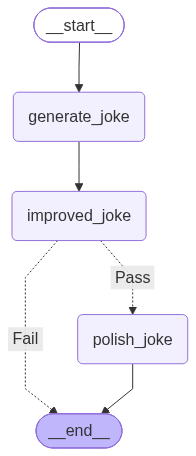

In [39]:
display(Image(chain.get_graph().draw_mermaid_png()))

In [42]:
state = chain.invoke({"topic": "owl"})
print("Initial Joke")
show(state["joke"])
if "improved_joke" in state:
    print("Improved Joke")
    show(state["improved_joke"])
    print("Final Joke")
    show(state["Final_joke"])


Initial Joke


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ 'Why don\'t owls ever get cold?  \nBecause they always have *hot dates*! 🦉🔥  \n\n*(Bonus: Hawks, not owls,    │
│ are the real "hot date" champions.)* 😏'                                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Improved Joke


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ '**Why don\'t owls ever get cold?**  \nBecause they always have *hot dates*… and they’re *hot to hoot*! 🦉🔥    │
│ \n*(Bonus: Hawks, not owls, are the real "hot date" champions — they’re *hawk*ing for love! 😏)*  \n\n**Puns    │
│ added:**  \n- **"Hot to hoot"**: Combines "hot" (temperature/attraction) with owls’ iconic sound.  \n-          │
│ **"Hawk*ing for love"**: Plays on "hawk" (bird) and "to hawk" (to aggressively pursue).  \n- **"Hot dates"**:   │
│ Double entendre (warm weather vs. romantic partners).  \n\nNow the joke’s *feather-light* with puns! 🦉✨'      │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Final Joke


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ '**Why don\'t owls ever get cold?**  \nBecause they always have *hot dates*… and they’re *hot to hoot*! 🦉🔥    │
│ \n*(Bonus: Hawks, not owls, are the real "hot date" champions — they’re *hawk*ing for love! 😏)*                │
│ \n\n**Surprising Twist:**  \nBut wait—*owls aren’t the only ones with a warm vibe*! 🌡️  \n**They’re actually    │
│ the *coolest* birds around**… because they’re *owl*ing at the *hot* spot of the night! 🌙✨  \n*(And yes,       │
│ that’s a pun. Now go hug a tree.)* 🌲  \n\n**Final Twist:**  \n*Wait for it…*  \n**Owls don’t get cold because  │
│ they’re already in the “hot zone”—the night!** 🌑🔥  \n*(Science says it’s thermoregulation. We say it’s        │
│ magic.)* 🧙\u200d♂️🦉'                                                                                          │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

### Orchestrator Worker

In [12]:
from typing_extensions import Annotated, List
import operator
from langchain.messages import HumanMessage, SystemMessage
class Section(BaseModel):
    name : str = Field(
        description="Name for this section of the report. ",
    )
    description : str = Field(
        description= " Brief overview of the main topics and concepts to be covered in this section."
    )
class Sections(BaseModel):
    plans : List[Section] = Field(
        description= "Sections of the report",
    )

planner = model.with_structured_output(Sections)

In [13]:
# States
class State(TypedDict):
    topic : str
    sections : list[Section]
    complete_sections : Annotated[
        list, operator.add
    ]
    final_report : str 
class WorkerState(TypedDict):
    section : Section
    completed_sections : Annotated[list, operator.add]

In [18]:
from langgraph.types import Send
# Nodes


def orchestrator(state: State):
    """ Generates a plan for the report """
    report_sections = planner.invoke([SystemMessage(
        "Generate a plan for this report"
    ), HumanMessage(
        content=f"Here is the topic {State["topic"]}"
    )])
    return {"sections" : report_sections.plans}

def llm_calls(state : WorkerState):
    section = model.invoke([SystemMessage(
        "Write a report on this topic"
    ), HumanMessage(
        content=f"Here is the topic {state["section"].name} and the description is {state["description"].description}." 
    )])
    return {"completed_sections" : [section.content]}

def synthesizer(state: State):
    completed_sections = state["completed_sections"]
    completed_report_sections = "\n\n---\n\n".join(completed_sections)
    return {"final_report" : completed_report_sections}

def assign_workers(state: State):
    return [Send("llm_call", {"section" : s}) for s in state["sections"]]



In [19]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

In [21]:
orchestrator_worker_builder = StateGraph(State)

orchestrator_worker_builder.add_node("orchestrator", orchestrator)
orchestrator_worker_builder.add_node("llm_call", llm_calls)
orchestrator_worker_builder.add_node("synthesizer", synthesizer)

orchestrator_worker_builder.add_edge(START, "orchestrator")
orchestrator_worker_builder.add_conditional_edges("orchestrator", assign_workers, ["llm_Call"])
orchestrator_worker_builder.add_edge("llm_Call", "synthesizer")
orchestrator_worker_builder.add_edge("synthesizer", END)

In [23]:
orchestrator_worker = orchestrator_worker_builder.compile()
display(Image(orchestrator_worker.get_graph().draw_mermaid_png()))

ValueError: Found edge starting at unknown node 'llm_Call'